In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Distribuição Gamma

## Exercício 1

Gere uma amostra de uma distribuição $\operatorname{Gamma}(k,\lambda)$, com $k$ inteiro, via soma de exponenciais. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

# Distribuição Beta

## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


Ex 1)

Text(0.5, 1.0, 'Dsitribuição Numpy')

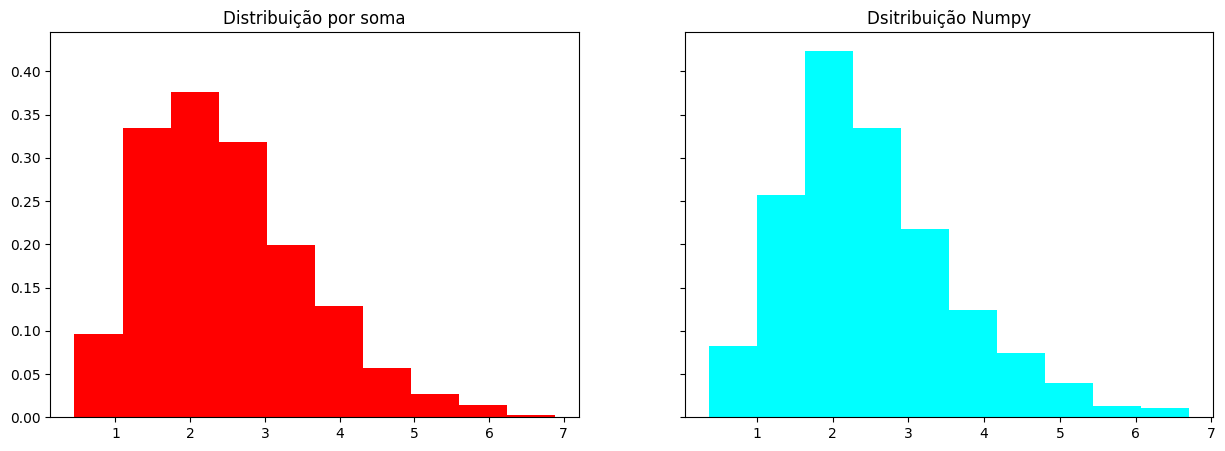

In [2]:
N = 1000
k = 5
amostra = []
lam = 2
for j in range(N):
  gama = []
  for i in range(k):
    U = np.random.uniform(0,1)
    X = -(1/lam)*np.log(1-U)
    gama.append(X)
  amostra.append(np.sum(gama))


amostra_numpy = np.random.gamma(5, 1/lam, 1000)
fig, axs= plt.subplots(1, 2, figsize= (15,5), sharey = True)
axs[0].hist(amostra, density = True, color = "Red")
axs[0].set_title('Distribuição por soma')
axs[1].hist(amostra_numpy, density = True, color = "Cyan")
axs[1].set_title('Dsitribuição Numpy')

In [3]:

def f(x, alpha, lamb):
  return ((lam**alpha) * (x**(alpha - 1))* np.exp(-(lam*x)))/math.gamma(alpha)
def g(x, teta):
  return (teta)*np.exp(-(x*teta))


Ex 2)

0.4193137922545478
2.3848488136372628


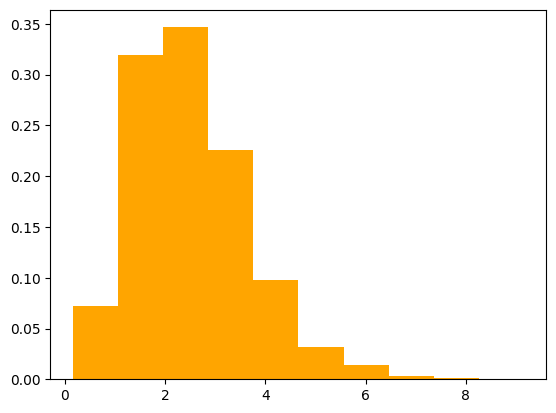

In [4]:
a = 5
N = 10000
amostra_gama = []
teta = lam / a
c = f((a - 1)/(lam - teta), a, lam)/g((a-1)/(lam-teta), teta)
prob_aceitação = 1/c
for i in range(N):
  u = np.random.uniform()
  Y = -(1/teta)*np.log(1-u)
  U = np.random.uniform()
  while c*U*g(Y, teta) > f(Y, a, lam):
    u = np.random.uniform()
    Y = -(1/teta)*np.log(1-u)
    U = np.random.uniform()
  x = Y
  amostra_gama.append(x)

plt.hist(amostra_gama, density = True, color = "Orange")
print(prob_aceitação)
print(c)

Ex 3)


(array([0.59514507, 0.05189827, 0.01415407, 0.00471802, 0.00337002,
        0.00202201, 0.        , 0.00202201, 0.        , 0.000674  ]),
 array([6.92672067e-03, 1.49059859e+00, 2.97427046e+00, 4.45794233e+00,
        5.94161420e+00, 7.42528608e+00, 8.90895795e+00, 1.03926298e+01,
        1.18763017e+01, 1.33599736e+01, 1.48436454e+01]),
 <BarContainer object of 10 artists>)

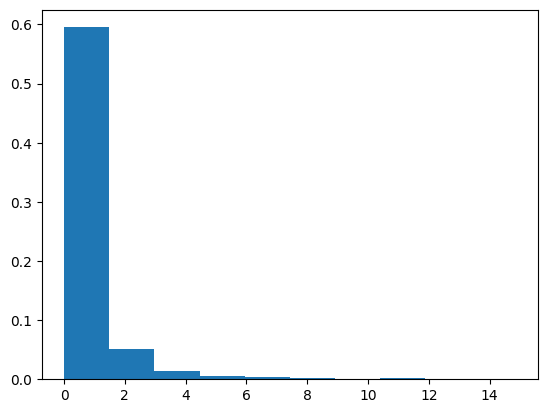

In [5]:
a = 1.9
lam = 4
N = 1000
amostra_gama2 = []
teta = lam / a
c = f((a - 1)/(lam - teta), a, lam)/g((a-1)/(lam-teta), teta)
prob_aceitação = 1/c
for i in range(N):
  u = np.random.uniform()
  Y = -(1/teta)*np.log(1-u)
  U = np.random.uniform()
  while c*U*g(Y, teta) > f(Y, a, lam):
    u = np.random.uniform()
    Y = -(1/teta)*np.log(1-u)
    U = np.random.uniform()
  G = Y
  l = np.random.uniform()
  X = G*(l**(1/a-1))
  amostra_gama2.append(X)
plt.hist(amostra_gama2, density = True)

Ex 4)

2.5109374015428108


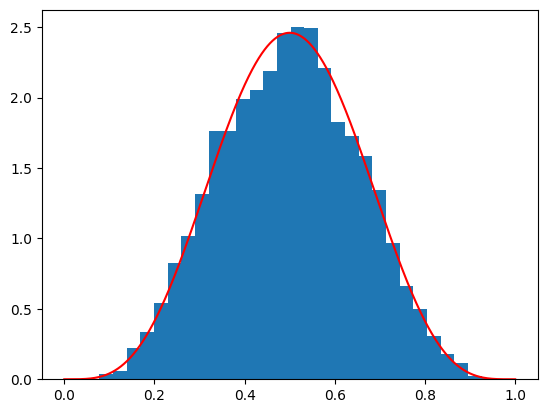

In [6]:
alpha = 5
beta = 5

def f_beta(x):
  return math.gamma(alpha + beta)/(math.gamma(alpha)*math.gamma(beta)) * x**(alpha-1) * (1-x)**(beta-1)

valor = []
for x in np.linspace(0, 1, 10_000):
  valor.append(f_beta(x))

c = np.max(valor)+0.05
print(c)

amostra = []

while len(amostra) < 10_000:
  u = np.random.uniform()
  y = np.random.uniform()

  if(u < f_beta(y)/c):
    amostra.append(y)

plt.hist(amostra, density=True, bins=30)
plt.plot(np.linspace(0, 1, 10_000), valor, color='red')
plt.show()


In [8]:
alpha = 5
beta = 15

G1 = np.array(gama(alpha, 1, 1_000))
G2 = np.array(gama(beta, 1, 1_000))

amostra = G1/(G1+G2)

plt.hist(amostra, density=True)
plt.show()

TypeError: 'list' object is not callable

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

ax[0].hist(amostra, density=True)
ax[0].set_title('Beta G1/(G1 + G2)')

num = np.random.beta(5, 15, 10_000)

ax[1].hist(num, density=True)
ax[1].set_title('Beta Numpy')

plt.show()